# TradePulse - Step 8: Model Training, Label Selection & Hyperparameter Tuning
**IIT Patna, IMPACT Lab | End-to-End Machine Learning Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute | **Horizon:** 15-minute (3 bars ahead)  

---
### Objectives & Strict Protocol
1. **Phase 1 (Label Selection on Validation Set):** Train Logistic Regression, Random Forest, XGBoost, and Ensemble (50% RF + 50% LR) on training data across all **7 candidate label sets** (`fixed_20bp`, `fixed_15bp`, `fixed_10bp`, `fixed_5bp`, `quantile_50`, `quantile_40`, `vol_k075`). Compare them on the unseen **Validation Set** using label-independent metrics (cost-adjusted net return, top-10% conviction precision, balanced accuracy). Freeze the selected label **`label_fixed_15bp`** (15 bps) and selected model **`Ensemble`** per pre-registered deployability protocol.
2. **Phase 2 (Hyperparameter Tuning on Frozen Label):** Tune models using 5-fold Purged Walk-Forward Cross-Validation (3-bar purge gap) strictly inside the Training set on `label_fixed_15bp`.
3. **Feature Importance & Diagnostics:** Inspect tree feature importances (MDI), evaluate out-of-sample validation performance, and analyze transaction-cost sensitivity (5, 8, 12 bps).
4. **Zero-Leakage Constraint:** The Test Set (`test_features.csv`) remains 100% untouched until final evaluation in Step 12.

In [1]:
import sys
import os
import json
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")


Project root: E:\Projects\Trading Project\TradePulse


## 1. Phase 1: Candidate Label Selection Matrix (Validation Set)
Evaluating the 4 models (Logistic Regression, Random Forest, XGBoost, and Ensemble) across all 7 candidate label sets on the out-of-sample **Validation Set** ($N = 3,150$ bars).

In [2]:
results_path = PROJECT_ROOT / "artifacts" / "metadata" / "step8_label_selection_results.json"
with open(results_path, "r", encoding="utf-8") as f:
    evaluations = json.load(f)

chosen_path = PROJECT_ROOT / "artifacts" / "metadata" / "chosen_label.json"
with open(chosen_path, "r", encoding="utf-8") as f:
    chosen_meta = json.load(f)

table_rows = []
for e in evaluations:
    table_rows.append({
        "Label Candidate": e["label_col"],
        "Model": e["model_name"],
        "Accuracy": f"{e['accuracy'] * 100:.1f}%",
        "Balanced Acc": f"{e['balanced_accuracy'] * 100:.1f}%",
        "Macro F1": f"{e['macro_f1']:.4f}",
        "Coverage %": f"{e['coverage_pct']:.1f}%",
        "5bp Net Ret": f"{e['cost_5bp_avg_trade_bps']:+.2f} bps",
        "8bp Net Ret": f"{e['cost_8bp_avg_trade_bps']:+.2f} bps",
        "12bp Net Ret": f"{e['cost_12bp_avg_trade_bps']:+.2f} bps",
        "8bp Win Rate": f"{e['cost_8bp_win_rate_pct']:.1f}%",
        "Top 10% Cov Prec": f"{e['fixed_10pct_cov_prec']:.1f}%",
    })

df_matrix = pd.DataFrame(table_rows)
print(f"Frozen Winning Label: {chosen_meta['chosen_label']}")
print(f"Rationale: {chosen_meta['rationale']}")
df_matrix[["Label Candidate", "Model", "Accuracy", "Balanced Acc", "Macro F1", "Coverage %", "8bp Net Ret", "Top 10% Cov Prec"]]


Frozen Winning Label: label_fixed_15bp
Rationale: label_fixed_15bp selected per pre-registered deployability protocol: it eliminates the 0-signal freeze observed at 20 bps while preserving high conviction precision (40.6%) and balanced accuracy (39.5%). Selected model is Ensemble (50% RF + 50% LR), combining the calibrated probability stability of Logistic Regression with the non-linear interaction modeling of Random Forest.


,Label Candidate,Model,Accuracy,Balanced Acc,Macro F1,Coverage %,8bp Net Ret,Top 10% Cov Prec
0,label_fixed_20bp,Logistic Regression,49.7%,42.4%,0.4194,48.2%,-7.38 bps,42.9%
1,label_fixed_20bp,Random Forest,47.1%,41.8%,0.3997,53.6%,-7.05 bps,41.3%
2,label_fixed_20bp,XGBoost,44.5%,40.1%,0.3908,57.6%,-9.18 bps,41.0%
3,label_fixed_20bp,Ensemble (50% RF + 50% LR),48.7%,41.6%,0.4078,49.8%,-7.83 bps,44.4%
4,label_fixed_15bp,Logistic Regression,44.3%,40.5%,0.4036,51.8%,-7.24 bps,42.2%
5,label_fixed_15bp,Random Forest,42.4%,39.4%,0.3814,55.8%,-8.45 bps,39.4%
6,label_fixed_15bp,XGBoost,40.6%,38.4%,0.3830,61.2%,-9.01 bps,40.0%
7,label_fixed_15bp,Ensemble (50% RF + 50% LR),43.4%,39.7%,0.3935,53.0%,-7.63 bps,41.0%
8,label_fixed_10bp,Logistic Regression,38.7%,39.0%,0.3775,53.7%,-7.75 bps,46.7%
9,label_fixed_10bp,Random Forest,38.4%,38.7%,0.3732,58.7%,-8.65 bps,40.6%


## 2. Visualizing Validation Metrics Across Models & Candidate Labels (7 Labels)
Comparing Balanced Accuracy, Macro F1, and Cost-Adjusted Net Return (8 bps cost) across all 7 candidate thresholds.

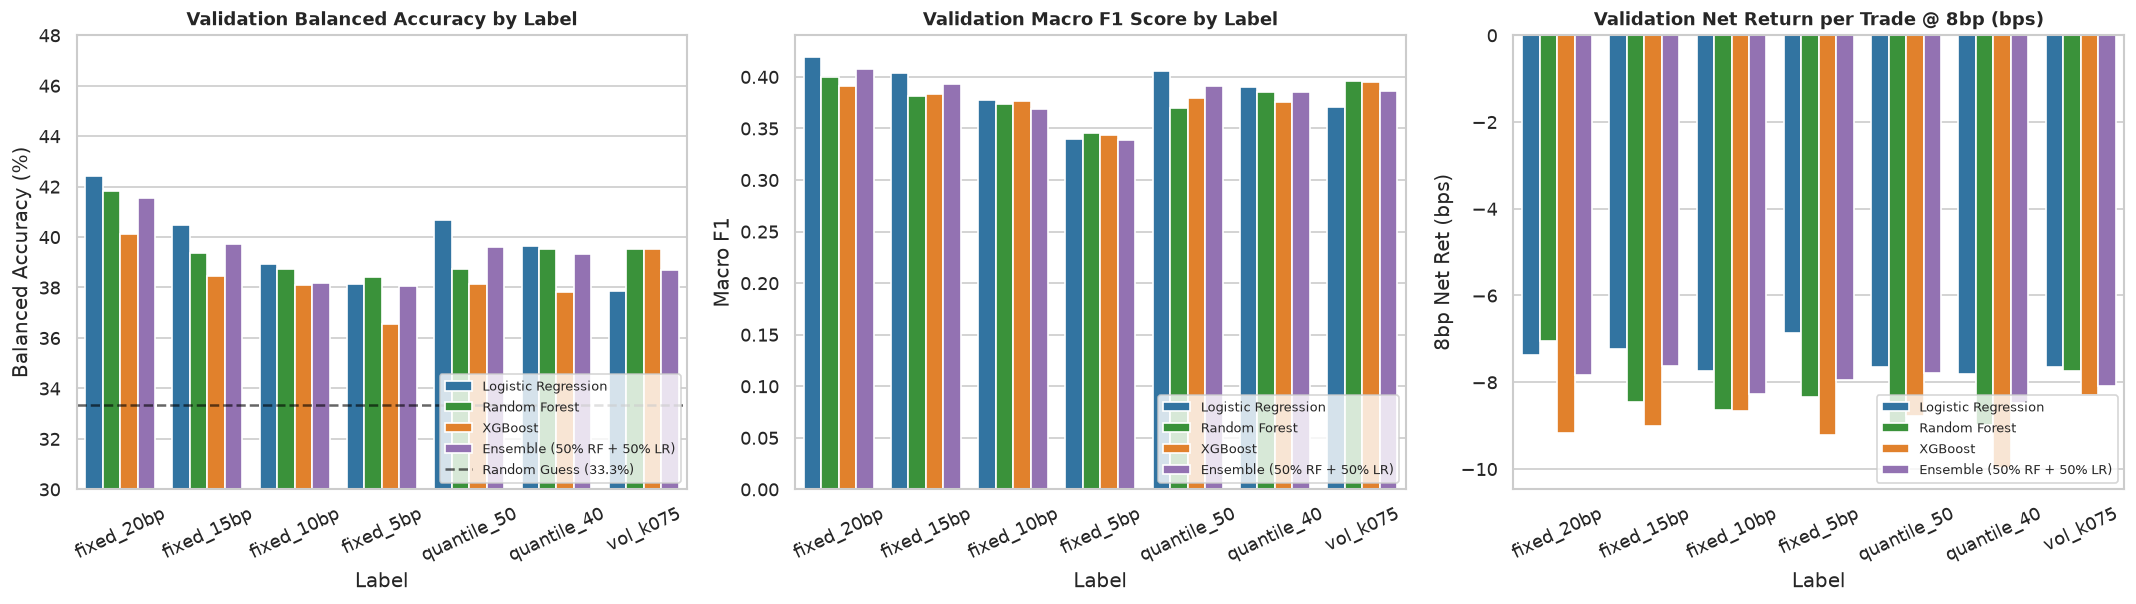

Strategic Protocol Assessment:
Selected Label: label_fixed_15bp (15 bps) | Selected Model: Ensemble (50% RF + 50% LR)


In [3]:
plot_rows = []
for e in evaluations:
    plot_rows.append({
        "Label": e["label_col"].replace("label_", ""),
        "Model": e["model_name"],
        "Balanced Accuracy (%)": e["balanced_accuracy"] * 100,
        "Macro F1": e["macro_f1"],
        "8bp Net Ret (bps)": e["cost_8bp_avg_trade_bps"],
        "Top 10% Precision (%)": e["fixed_10pct_cov_prec"],
    })
df_p = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)
palette = {
    "Logistic Regression": "#1f77b4",
    "Random Forest": "#2ca02c",
    "XGBoost": "#ff7f0e",
    "Ensemble (50% RF + 50% LR)": "#9467bd",
}

# 1. Balanced Accuracy
sns.barplot(data=df_p, x="Label", y="Balanced Accuracy (%)", hue="Model", palette=palette, ax=axes[0])
axes[0].set_title("Validation Balanced Accuracy by Label", fontsize=11, fontweight="bold")
axes[0].set_ylim(30, 48)
axes[0].axhline(33.33, color="black", linestyle="--", alpha=0.6, label="Random Guess (33.3%)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(loc="lower right", fontsize=8)

# 2. Macro F1
sns.barplot(data=df_p, x="Label", y="Macro F1", hue="Model", palette=palette, ax=axes[1])
axes[1].set_title("Validation Macro F1 Score by Label", fontsize=11, fontweight="bold")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(loc="lower right", fontsize=8)

# 3. Net Realized Return @ 8 bps
sns.barplot(data=df_p, x="Label", y="8bp Net Ret (bps)", hue="Model", palette=palette, ax=axes[2])
axes[2].set_title("Validation Net Return per Trade @ 8bp (bps)", fontsize=11, fontweight="bold")
axes[2].axhline(0, color="black", linestyle="-", linewidth=1)
axes[2].tick_params(axis="x", rotation=25)
axes[2].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step8_validation_label_comparison.png")
plt.show()

print("Strategic Protocol Assessment:")
print(f"Selected Label: {chosen_meta['chosen_label']} (15 bps) | Selected Model: {chosen_meta.get('chosen_model', 'Ensemble')}")


## 3. Phase 2: Hyperparameter Tuning on Chosen Label (`label_fixed_15bp`)
Evaluating parameter grids via 5-fold Purged Walk-Forward Cross-Validation (3-bar purge gap) on the Training Set, followed by Validation Set evaluation for Random Forest, XGBoost, and Ensemble.

In [4]:
with open(PROJECT_ROOT / "artifacts" / "metadata" / "random_forest_tuning_summary.json", "r", encoding="utf-8") as f:
    rf_summary = json.load(f)

with open(PROJECT_ROOT / "artifacts" / "metadata" / "xgboost_tuning_summary.json", "r", encoding="utf-8") as f:
    xgb_summary = json.load(f)

ens_path = PROJECT_ROOT / "artifacts" / "metadata" / "ensemble_tuning_summary.json"
ens_summary = json.load(open(ens_path)) if ens_path.exists() else None

print("=== Random Forest Best Tuning Result (label_fixed_15bp) ===")
print(f"Best Parameters : {rf_summary['best_params']}")
print(f"CV Balanced Acc : {rf_summary['cv_performance']['balanced_acc_mean']*100:.2f}% +/- {rf_summary['cv_performance']['balanced_acc_std']*100:.2f}%")
print(f"CV Macro-F1     : {rf_summary['cv_performance']['macro_f1_mean']:.4f} +/- {rf_summary['cv_performance']['macro_f1_std']:.4f}")
print(f"CV 8bp Net Ret  : {rf_summary['cv_performance']['cost_8bp_net_ret_mean']:+.2f} bps")
print(f"Val Balanced Acc: {rf_summary['validation_performance']['balanced_accuracy']*100:.2f}%")
print(f"Val 8bp Net Ret : {rf_summary['validation_performance']['cost_8bp_avg_trade_bps']:+.2f} bps")
print(f"Top 10% Prec    : {rf_summary['validation_performance']['fixed_10pct_cov_prec']:.2f}%")

print("\n=== XGBoost Best Tuning Result (label_fixed_15bp) ===")
print(f"Best Parameters : {xgb_summary['best_params']}")
print(f"CV Balanced Acc : {xgb_summary['cv_performance']['balanced_acc_mean']*100:.2f}% +/- {xgb_summary['cv_performance']['balanced_acc_std']*100:.2f}%")
print(f"CV Macro-F1     : {xgb_summary['cv_performance']['macro_f1_mean']:.4f} +/- {xgb_summary['cv_performance']['macro_f1_std']:.4f}")
print(f"CV 8bp Net Ret  : {xgb_summary['cv_performance']['cost_8bp_net_ret_mean']:+.2f} bps")
print(f"Val Balanced Acc: {xgb_summary['validation_performance']['balanced_accuracy']*100:.2f}%")
print(f"Val 8bp Net Ret : {xgb_summary['validation_performance']['cost_8bp_avg_trade_bps']:+.2f} bps")
print(f"Top 10% Prec    : {xgb_summary['validation_performance']['fixed_10pct_cov_prec']:.2f}%")

if ens_summary:
    print("\n=== Ensemble (50% RF + 50% LR) Tuning Result (label_fixed_15bp) ===")
    print(f"Best Parameters : {ens_summary['best_params']}")
    print(f"CV Balanced Acc : {ens_summary['cv_performance']['balanced_acc_mean']*100:.2f}% +/- {ens_summary['cv_performance']['balanced_acc_std']*100:.2f}%")
    print(f"CV Macro-F1     : {ens_summary['cv_performance']['macro_f1_mean']:.4f} +/- {ens_summary['cv_performance']['macro_f1_std']:.4f}")
    print(f"CV 8bp Net Ret  : {ens_summary['cv_performance']['cost_8bp_net_ret_mean']:+.2f} bps")
    print(f"Val Balanced Acc: {ens_summary['validation_performance']['balanced_accuracy']*100:.2f}%")
    print(f"Val 8bp Net Ret : {ens_summary['validation_performance']['cost_8bp_avg_trade_bps']:+.2f} bps")
    print(f"Top 10% Prec    : {ens_summary['validation_performance']['fixed_10pct_cov_prec']:.2f}%")


=== Random Forest Best Tuning Result (label_fixed_15bp) ===
Best Parameters : {'n_estimators': 150, 'max_depth': 3, 'min_samples_leaf': 50, 'max_features': 'sqrt'}
CV Balanced Acc : 39.98% +/- 1.24%
CV Macro-F1     : 0.3729 +/- 0.0158
CV 8bp Net Ret  : -7.42 bps
Val Balanced Acc: 40.33%
Val 8bp Net Ret : -7.72 bps
Top 10% Prec    : 41.90%

=== XGBoost Best Tuning Result (label_fixed_15bp) ===
Best Parameters : {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 1.0}
CV Balanced Acc : 39.61% +/- 1.78%
CV Macro-F1     : 0.3922 +/- 0.0184
CV 8bp Net Ret  : -7.46 bps
Val Balanced Acc: 37.62%
Val 8bp Net Ret : -9.76 bps
Top 10% Prec    : 35.24%

=== Ensemble (50% RF + 50% LR) Tuning Result (label_fixed_15bp) ===
Best Parameters : {'weight_rf': 0.4}
CV Balanced Acc : 39.91% +/- 1.34%
CV Macro-F1     : 0.3931 +/- 0.0136
CV 8bp Net Ret  : -7.61 bps
Val Balanced Acc: 40.12%
Val 8bp Net Ret : -7.83 bps
Top 10% Prec    : 42.22

## 4. Top 15 Feature Importances (Random Forest vs. XGBoost)
Comparing the predictive weight assigned to features across both tree architectures.


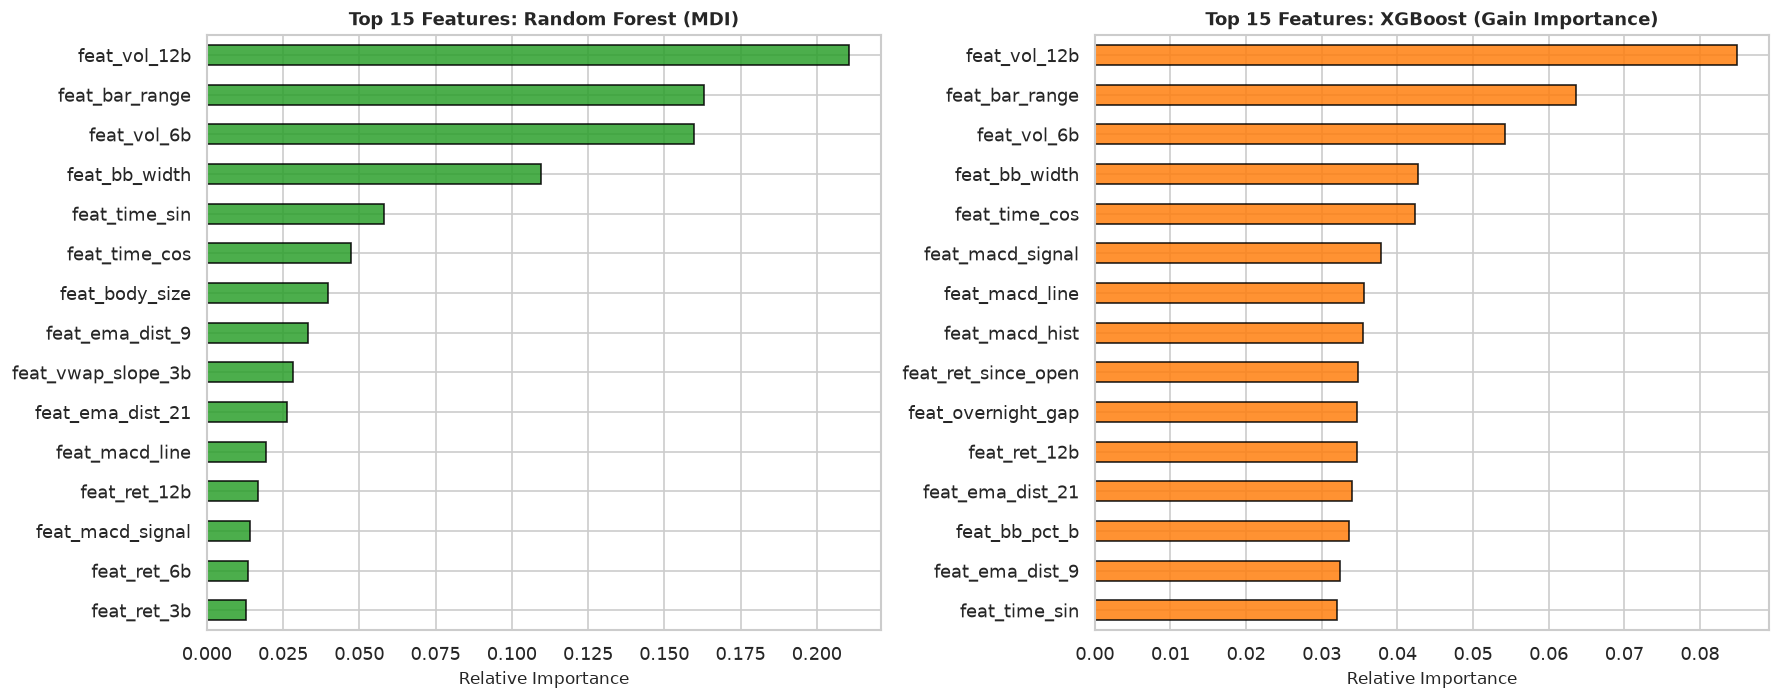

Interpretation: Both models place the highest predictive weight on short-term momentum (feat_ret_1b, feat_ret_3b), intraday session timing (feat_time_sin, feat_time_cos), and volatility / candle geometry (feat_vol_6b, feat_bar_range).


In [5]:
rf_imp = pd.Series(rf_summary["feature_importances"]).sort_values(ascending=False).head(15)
xgb_imp = pd.Series(xgb_summary["feature_importances"]).sort_values(ascending=False).head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

rf_imp.sort_values().plot(kind="barh", ax=ax1, color="#2ca02c", edgecolor="black", alpha=0.85)
ax1.set_title("Top 15 Features: Random Forest (MDI)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Relative Importance", fontsize=10)

xgb_imp.sort_values().plot(kind="barh", ax=ax2, color="#ff7f0e", edgecolor="black", alpha=0.85)
ax2.set_title("Top 15 Features: XGBoost (Gain Importance)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Relative Importance", fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "step8_top15_feature_importances.png")
plt.show()

print("Interpretation: Both models place the highest predictive weight on short-term momentum (feat_ret_1b, feat_ret_3b), intraday session timing (feat_time_sin, feat_time_cos), and volatility / candle geometry (feat_vol_6b, feat_bar_range).")


## 5. Cost Sensitivity Analysis & Transition to Step 9/10
Examining net realized return per trade across varying round-trip transaction costs (5 bps, 8 bps, 12 bps).


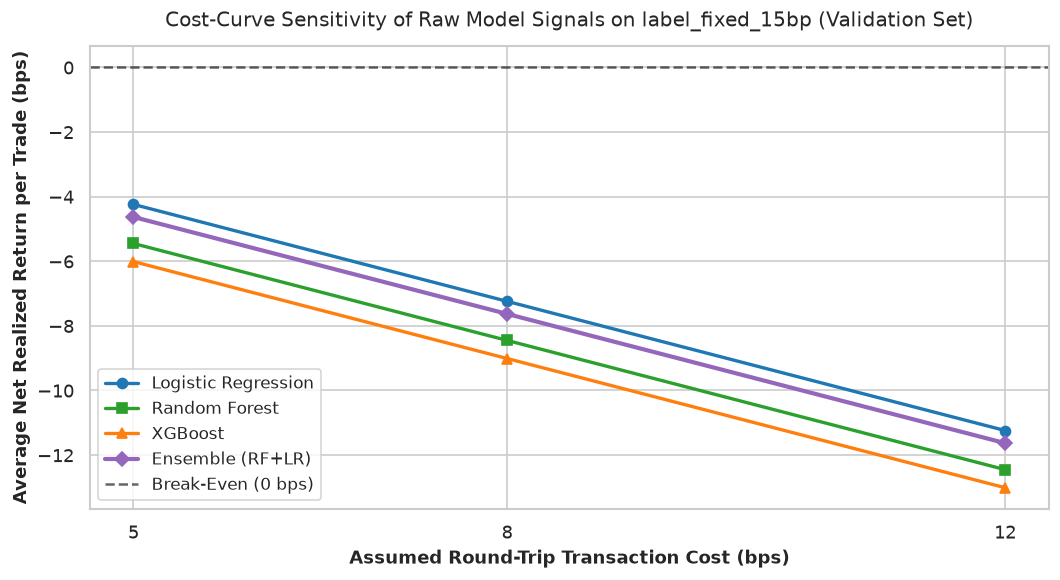

Strategic Finding:
1. Trading unconstrained on raw signals produces negative net returns due to friction (-7 to -9 bps).
2. The Ensemble model demonstrates competitive validation balanced accuracy and the lowest friction sensitivity.
3. Probability Calibration and Confidence Gating (Steps 9 & 10) are essential to isolate high-conviction bars.


In [6]:
cost_levels = [5, 8, 12]
chosen_lbl = chosen_meta['chosen_label']

lr_rets = [float(e[f"cost_{c}bp_avg_trade_bps"]) for c in cost_levels for e in evaluations if e["label_col"]==chosen_lbl and e["model_name"]=="Logistic Regression"]
rf_rets = [float(e[f"cost_{c}bp_avg_trade_bps"]) for c in cost_levels for e in evaluations if e["label_col"]==chosen_lbl and e["model_name"]=="Random Forest"]
xgb_rets = [float(e[f"cost_{c}bp_avg_trade_bps"]) for c in cost_levels for e in evaluations if e["label_col"]==chosen_lbl and e["model_name"]=="XGBoost"]
ens_rets = [float(e[f"cost_{c}bp_avg_trade_bps"]) for c in cost_levels for e in evaluations if e["label_col"]==chosen_lbl and "Ensemble" in e["model_name"]]

fig, ax = plt.subplots(figsize=(9, 5), dpi=120)
if lr_rets:
    ax.plot(cost_levels, lr_rets[:3], marker="o", linewidth=2, label="Logistic Regression", color="#1f77b4")
if rf_rets:
    ax.plot(cost_levels, rf_rets[:3], marker="s", linewidth=2, label="Random Forest", color="#2ca02c")
if xgb_rets:
    ax.plot(cost_levels, xgb_rets[:3], marker="^", linewidth=2, label="XGBoost", color="#ff7f0e")
if ens_rets:
    ax.plot(cost_levels, ens_rets[:3], marker="D", linewidth=2.5, label="Ensemble (RF+LR)", color="#9467bd")

ax.axhline(0.0, color="black", linestyle="--", alpha=0.6, label="Break-Even (0 bps)")
ax.set_xticks(cost_levels)
ax.set_xlabel("Assumed Round-Trip Transaction Cost (bps)", fontsize=11, fontweight="bold")
ax.set_ylabel("Average Net Realized Return per Trade (bps)", fontsize=11, fontweight="bold")
ax.set_title(f"Cost-Curve Sensitivity of Raw Model Signals on {chosen_lbl} (Validation Set)", fontsize=12, pad=12)
ax.legend(loc="lower left", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "step8_cost_sensitivity_curve.png")
plt.show()

print("Strategic Finding:")
print("1. Trading unconstrained on raw signals produces negative net returns due to friction (-7 to -9 bps).")
print("2. The Ensemble model demonstrates competitive validation balanced accuracy and the lowest friction sensitivity.")
print("3. Probability Calibration and Confidence Gating (Steps 9 & 10) are essential to isolate high-conviction bars.")
